# T14 — Tests complémentaires et robustesse

Ce notebook ne modifie aucun résultat principal : il lit les prévisions de `results/` et écrit ses sorties à part (tables 7 à 12, `results/robustesse/`, figure 6). Il répond aux points restés ouverts avant le gel des résultats :

1. LightGBM contre GARCH, GJR et EGARCH (Diebold-Mariano direct) ;
2. stabilité dans le temps : sous-périodes 2015-2019, 2020, 2021-2026 ;
3. tests multiples : correction de Holm ;
4. grille de LightGBM qui touche son bord : réglage sur une grille élargie ;
5. donnée douteuse du TSX du 2008-10-14 (rv = 124,9) : sensibilité ;
6. interprétation de LightGBM avec SHAP.

À exécuter après `06_resultats`.

In [1]:
import sys, warnings
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import lightgbm as lgb
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "data" / "features_spx.csv").exists())
sys.path.append(str(root))
from src.utils import TEST_START, HORIZONS, load_all_forecasts, dm_test, qlike, mse

RES = root / "results"
ROB = RES / "robustesse"
ROB.mkdir(exist_ok=True)
FEAT = {k: pd.read_csv(root / "data" / f"features_{k}.csv", index_col=0, parse_dates=True)
        for k in ("spx", "tsx")}
FC = {k: load_all_forecasts(k) for k in ("spx", "tsx")}

def wide(ix, h):
    """Prévisions de tous les modèles à l'horizon h (une colonne par modèle) et cible."""
    g = FC[ix][FC[ix]["horizon"] == h]
    w = g.pivot(index="date", columns="model", values="forecast").dropna()
    y = g.drop_duplicates("date").set_index("date").loc[w.index, "actual"]
    return w, y

print({k: sorted(v["model"].unique()) for k, v in FC.items()})

{'spx': ['EGARCH', 'GARCH', 'GJR', 'HAR', 'HARX', 'LGBM', 'LGBM_noVIX', 'LOGHAR', 'LOGHARX'], 'tsx': ['EGARCH', 'GARCH', 'GJR', 'HAR', 'HARX', 'LGBM', 'LGBM_noVIX', 'LOGHAR', 'LOGHARX']}


## 1. LightGBM contre la famille GARCH

Statistique DM négative : LightGBM est meilleur. Erreurs HAC avec h retards, comme partout ailleurs.

In [2]:
rows = []
for ix in FC:
    for h in HORIZONS:
        w, y = wide(ix, h)
        for b in ["GARCH", "GJR", "EGARCH"]:
            t, p = dm_test(y, w["LGBM"], w[b], h)
            rows.append({"indice": ix, "horizon": h, "comparaison": f"LGBM vs {b}",
                         "QLIKE_LGBM": qlike(y, w["LGBM"]), f"QLIKE_ref": qlike(y, w[b]),
                         "écart_%": 100 * (qlike(y, w["LGBM"]) / qlike(y, w[b]) - 1),
                         "DM": t, "p-value": p})
table7 = pd.DataFrame(rows).round(4)
table7.to_csv(RES / "table7_dm_lgbm_garch.csv", index=False)
display(table7)

,indice,horizon,comparaison,QLIKE_LGBM,QLIKE_ref,écart_%,DM,p-value
0,spx,1,LGBM vs GARCH,0.3421,0.4210,-18.7318,-8.1279,0.0000
1,spx,1,LGBM vs GJR,0.3421,0.3939,-13.1405,-3.9917,0.0001
2,spx,1,LGBM vs EGARCH,0.3421,0.4060,-15.7243,-3.7098,0.0002
3,spx,5,LGBM vs GARCH,0.2320,0.3035,-23.5535,-5.6859,0.0000
4,spx,5,LGBM vs GJR,0.2320,0.2907,-20.1736,-3.0306,0.0024
5,spx,5,LGBM vs EGARCH,0.2320,0.3135,-25.9941,-2.9097,0.0036
6,spx,22,LGBM vs GARCH,0.3164,0.3182,-0.5775,-0.0737,0.9412
7,spx,22,LGBM vs GJR,0.3164,0.3250,-2.6476,-0.4132,0.6794
8,spx,22,LGBM vs EGARCH,0.3164,0.3846,-17.7466,-1.3898,0.1646
9,tsx,1,LGBM vs GARCH,0.2968,0.3529,-15.9073,-7.0191,0.0000


## 2. Sous-périodes

Même prévisions, évaluées séparément sur 2015-2019 (calme), 2020 (choc COVID) et 2021-2026. La date est celle de la prévision. En 2020, il n'y a qu'environ 250 prévisions et, à h = 22, elles se chevauchent fortement : la puissance des tests est faible.

In [3]:
PERIODES = {"2015-2019": ("2015-01-01", "2019-12-31"),
            "2020": ("2020-01-01", "2020-12-31"),
            "2021-2026": ("2021-01-01", "2026-12-31")}
MODELES = ["HAR", "LOGHARX", "LGBM", "LGBM_noVIX", "GJR", "EGARCH"]
rows = []
for ix in FC:
    for h in HORIZONS:
        w, y = wide(ix, h)
        for nom, (a, b) in PERIODES.items():
            m = (w.index >= a) & (w.index <= b)
            row = {"indice": ix, "horizon": h, "période": nom, "n": int(m.sum())}
            row |= {f"QLIKE_{k}": qlike(y[m], w.loc[m, k]) for k in MODELES}
            for ref in ["HAR", "LOGHARX"]:
                t, p = dm_test(y[m], w.loc[m, "LGBM"], w.loc[m, ref], h)
                row[f"LGBM/{ref}_%"] = 100 * (row["QLIKE_LGBM"] / row[f"QLIKE_{ref}"] - 1)
                row[f"DM_vs_{ref}"], row[f"p_vs_{ref}"] = t, p
            rows.append(row)
table8 = pd.DataFrame(rows).round(4)
table8.to_csv(RES / "table8_sousperiodes.csv", index=False)
pd.set_option("display.width", 250)
display(table8[["indice", "horizon", "période", "n", "QLIKE_HAR", "QLIKE_LOGHARX", "QLIKE_LGBM",
                "LGBM/HAR_%", "p_vs_HAR", "LGBM/LOGHARX_%", "p_vs_LOGHARX"]])

,indice,horizon,période,n,QLIKE_HAR,QLIKE_LOGHARX,QLIKE_LGBM,LGBM/HAR_%,p_vs_HAR,LGBM/LOGHARX_%,p_vs_LOGHARX
0,spx,1,2015-2019,1258,0.4275,0.3508,0.3617,-15.3833,0.0000,3.1135,0.0913
1,spx,1,2020,253,0.4305,0.4002,0.3848,-10.5974,0.1771,-3.8498,0.2343
2,spx,1,2021-2026,1428,0.3621,0.3186,0.3173,-12.3767,0.0001,-0.4159,0.7720
3,spx,5,2015-2019,1258,0.3036,0.2423,0.2582,-14.9731,0.0006,6.5680,0.0013
4,spx,5,2020,253,0.3790,0.3220,0.2880,-24.0165,0.0634,-10.5782,0.0294
5,spx,5,2021-2026,1428,0.2321,0.1999,0.1991,-14.2064,0.0002,-0.4156,0.8131
6,spx,22,2015-2019,1258,0.3205,0.2757,0.3308,3.2141,0.8730,19.9507,0.0172
7,spx,22,2020,253,0.8710,0.9539,0.9340,7.2376,0.5409,-2.0814,0.5896
8,spx,22,2021-2026,1428,0.2070,0.1897,0.1942,-6.1811,0.3021,2.4112,0.3392
9,tsx,1,2015-2019,1254,0.3618,0.2974,0.2997,-17.1772,0.0000,0.7676,0.6536


## 3. Tests multiples : correction de Holm

Avec beaucoup de tests à 5 %, certains rejets sont dus au hasard. La procédure de Holm contrôle la probabilité de faire au moins un faux rejet dans une famille de tests (FWER). Elle trie les p-values de la plus petite à la plus grande et compare la k-ième à 0,05 / (m − k + 1). On l'applique à deux familles :

- **famille A, la question de recherche** : LightGBM contre HAR et LightGBM contre log-HAR-X (12 tests) ;
- **famille B, tous les tests de Diebold-Mariano** du projet (tables 4, VIX, log-HAR et 7).

In [4]:
tests = []
for ix in FC:
    t4 = pd.read_csv(RES / f"table4_resultats_{ix}.csv").dropna(subset=["p-value"])
    for _, r in t4.iterrows():
        tests.append({"indice": ix, "horizon": r["horizon"], "test": f"{r['model']} vs HAR",
                      "DM": r["DM vs HAR"], "p": r["p-value"]})
for _, r in pd.read_csv(RES / "table_vix_dm.csv").iterrows():
    tests.append({"indice": r["indice"], "horizon": r["horizon"], "test": "LGBM vs LGBM_noVIX",
                  "DM": r["DM"], "p": r["p-value"]})
for _, r in pd.read_csv(RES / "table_dm_lgbm_loghar.csv").iterrows():
    tests.append({"indice": r["indice"], "horizon": r["horizon"], "test": r["comparaison"],
                  "DM": r["DM"], "p": r["p-value"]})
for _, r in table7.iterrows():
    tests.append({"indice": r["indice"], "horizon": r["horizon"], "test": r["comparaison"],
                  "DM": r["DM"], "p": r["p-value"]})
table9 = pd.DataFrame(tests)
table9["horizon"] = table9["horizon"].astype(int)

A = table9["test"].isin(["LGBM vs HAR", "LGBM vs LOGHARX"])
table9["famille_A"] = A
table9.loc[A, "p_Holm_A"] = multipletests(table9.loc[A, "p"], method="holm")[1]
table9["p_Holm_B"] = multipletests(table9["p"], method="holm")[1]
table9["rejet_5%_brut"] = table9["p"] < 0.05
table9["rejet_5%_Holm_B"] = table9["p_Holm_B"] < 0.05
table9 = table9.round(4)
table9.to_csv(RES / "table9_holm.csv", index=False)

print("Famille B :", len(table9), "tests ;", int(table9["rejet_5%_brut"].sum()), "rejets bruts à 5 % ;",
      int(table9["rejet_5%_Holm_B"].sum()), "rejets après Holm")
print("\nFamille A (question de recherche) :")
display(table9[A][["indice", "horizon", "test", "DM", "p", "p_Holm_A", "p_Holm_B"]])
print("Rejets bruts qui ne survivent pas à Holm (famille B) :")
display(table9[table9["rejet_5%_brut"] & ~table9["rejet_5%_Holm_B"]])

Famille B : 84 tests ; 37 rejets bruts à 5 % ; 24 rejets après Holm

Famille A (question de recherche) :


,indice,horizon,test,DM,p,p_Holm_A,p_Holm_B
4,spx,1,LGBM vs HAR,-6.4970,0.0000,0.0000,0.0
12,spx,5,LGBM vs HAR,-5.2434,0.0000,0.0000,0.0
20,spx,22,LGBM vs HAR,0.1220,0.9029,1.0000,1.0
28,tsx,1,LGBM vs HAR,-8.0151,0.0000,0.0000,0.0
36,tsx,5,LGBM vs HAR,-5.2266,0.0000,0.0000,0.0
44,tsx,22,LGBM vs HAR,0.2748,0.7835,1.0000,1.0
54,spx,1,LGBM vs LOGHARX,0.7250,0.4682,1.0000,1.0
56,spx,5,LGBM vs LOGHARX,1.1190,0.2629,1.0000,1.0
58,spx,22,LGBM vs LOGHARX,2.2040,0.0276,0.2208,1.0
60,tsx,1,LGBM vs LOGHARX,-1.4270,0.1536,1.0000,1.0


Rejets bruts qui ne survivent pas à Holm (famille B) :


,indice,horizon,test,DM,p,famille_A,p_Holm_A,p_Holm_B,rejet_5%_brut,rejet_5%_Holm_B
1,spx,1,GARCH vs HAR,2.7611,0.0058,False,NaN,0.3248,True,False
6,spx,1,LOGHAR vs HAR,-2.5614,0.0104,False,NaN,0.5512,True,False
9,spx,5,GARCH vs HAR,2.2989,0.0215,False,NaN,1.0000,True,False
13,spx,5,LGBM_noVIX vs HAR,-2.0971,0.0360,False,NaN,1.0000,True,False
35,tsx,5,HARX vs HAR,2.7464,0.0060,False,NaN,0.3300,True,False
49,spx,5,LGBM vs LGBM_noVIX,-2.8900,0.0039,False,NaN,0.2262,True,False
51,tsx,1,LGBM vs LGBM_noVIX,-2.7710,0.0056,False,NaN,0.3192,True,False
55,spx,1,LGBM_noVIX vs LOGHAR,-2.5760,0.0100,False,NaN,0.5400,True,False
58,spx,22,LGBM vs LOGHARX,2.2040,0.0276,True,0.2208,1.0000,True,False
61,tsx,1,LGBM_noVIX vs LOGHAR,-2.3290,0.0198,False,NaN,1.0000,True,False


## 4. Grille de LightGBM élargie

Dans `05_lightgbm_T11`, les valeurs retenues touchent souvent le bord de la grille (num_leaves = 7, min_child_samples = 50, les plus petites valeurs testées). Si l'optimum est au-delà du bord, le modèle est peut-être mal réglé. On reprend exactement la même procédure (mêmes paramètres fixes, validation croisée chronologique à 4 plis avec un écart de 22, purge des cibles qui débordent sur 2015, QLIKE moyenne) avec une grille qui s'étend au-delà de ces bords : num_leaves ∈ {3, 5, 7, 15}, min_child_samples ∈ {10, 20, 50, 200}. Les prévisions sont écrites dans `results/robustesse/` pour ne pas remplacer celles du modèle principal.

In [5]:
X_COLS = ["rv_d", "rv_w", "rv_m", "ret", "ret_neg", "vix"]
VARIANTS = {"LGBM": X_COLS, "LGBM_noVIX": [c for c in X_COLS if c != "vix"]}
PARAMS = dict(objective="gamma", subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              random_state=42, verbose=-1, n_jobs=2)               # identiques à T11
GRID2 = {"num_leaves": [3, 5, 7, 15], "learning_rate": [0.01, 0.03],
         "min_child_samples": [10, 20, 50, 200], "n_estimators": [300, 800]}

def tune(frame, h, x_cols, grid):
    """Copie de la fonction de T11."""
    target = f"y_h{h}"
    target_end = frame.index.to_series().shift(-h)
    train = frame.loc[(frame.index >= "2000-01-01") & (target_end < TEST_START)].dropna(subset=[target])
    x, y = train[x_cols], train[target]
    folds = list(TimeSeriesSplit(n_splits=4, gap=22).split(train))
    out = []
    for values in product(*grid.values()):
        cand = dict(zip(grid, values))
        sc = []
        for fi, vi in folds:
            m = lgb.LGBMRegressor(**(PARAMS | cand)).fit(x.iloc[fi], y.iloc[fi])
            sc.append(qlike(y.iloc[vi].to_numpy(), np.maximum(m.predict(x.iloc[vi]), 1e-4)))
        out.append(cand | {"QLIKE_cv": float(np.mean(sc))})
    return pd.DataFrame(out).sort_values("QLIKE_cv", kind="stable").reset_index(drop=True)

def lgb_walk_forward(frame, h, params, x_cols, refit=66):
    """Copie de la fonction de T11 (ré-estimation tous les 66 jours)."""
    target = f"y_h{h}"
    dates = frame.index[(frame.index >= TEST_START) & frame[target].notna()]
    f = []
    for s, d in enumerate(dates):
        if s % refit == 0:
            tr = frame.loc[:d].iloc[:-h].dropna(subset=[target])
            model = lgb.LGBMRegressor(**params).fit(tr[x_cols], tr[target])
        f.append(max(float(model.predict(frame.loc[[d], x_cols])[0]), 1e-4))
    return pd.Series(f, index=dates)

t5 = pd.read_csv(RES / "table5_lgbm_params.csv")
rows = []
for ix, frame in FEAT.items():
    for name, cols in VARIANTS.items():
        for h in HORIZONS:
            best = tune(frame, h, cols, GRID2).iloc[0]
            new = {k: type(v[0])(best[k]) for k, v in GRID2.items()}
            old = t5[(t5["index"] == ix) & (t5["model"] == name) & (t5["horizon"] == h)].iloc[0]
            old_p = {k: type(v[0])(old[k]) for k, v in GRID2.items()}
            w, y = wide(ix, h)
            if new == old_p:                     # même choix : mêmes prévisions
                f_new = w[name]
            else:
                f_new = lgb_walk_forward(frame, h, PARAMS | new, cols).loc[w.index]
            pd.DataFrame({"date": w.index, "model": name + "_grille2", "horizon": h,
                          "forecast": f_new.values, "actual": y.values}).to_csv(
                ROB / f"forecasts_{ix}_{name}_grille2_h{h}.csv", index=False)
            ref = "LOGHARX" if name == "LGBM" else "LOGHAR"
            t_o, p_o = dm_test(y, f_new, w[name], h)
            t_r, p_r = dm_test(y, f_new, w[ref], h)
            rows.append({"indice": ix, "modèle": name, "horizon": h,
                         **{f"{k}_T11": old_p[k] for k in ("num_leaves", "min_child_samples", "learning_rate", "n_estimators")},
                         **{f"{k}_grille2": new[k] for k in ("num_leaves", "min_child_samples", "learning_rate", "n_estimators")},
                         "même_choix": new == old_p, "bord_grille2": new["num_leaves"] == 3 or new["min_child_samples"] == 10,
                         "QLIKE_cv_T11": old["QLIKE_cv"], "QLIKE_cv_grille2": best["QLIKE_cv"],
                         "QLIKE_test_T11": qlike(y, w[name]), "QLIKE_test_grille2": qlike(y, f_new),
                         "p_vs_T11": p_o, f"QLIKE_{ref}": qlike(y, w[ref]), "p_vs_log": p_r})
            print(ix, name, h, "fait", flush=True)
table10 = pd.DataFrame(rows).round(4)
table10.to_csv(RES / "table10_grille_elargie.csv", index=False)
display(table10)

spx LGBM 1 fait


spx LGBM 5 fait


spx LGBM 22 fait


spx LGBM_noVIX 1 fait


spx LGBM_noVIX 5 fait


spx LGBM_noVIX 22 fait


... (3 outputs left out)

tsx LGBM_noVIX 1 fait


tsx LGBM_noVIX 5 fait


tsx LGBM_noVIX 22 fait


,indice,modèle,horizon,num_leaves_T11,min_child_samples_T11,learning_rate_T11,n_estimators_T11,num_leaves_grille2,min_child_samples_grille2,learning_rate_grille2,...,même_choix,bord_grille2,QLIKE_cv_T11,QLIKE_cv_grille2,QLIKE_test_T11,QLIKE_test_grille2,p_vs_T11,QLIKE_LOGHARX,p_vs_log,QLIKE_LOGHAR
0,spx,LGBM,1,7,50,0.01,800,3,10,0.03,...,False,True,0.3534,0.3166,0.3421,0.3449,0.3029,0.3394,0.3079,NaN
1,spx,LGBM,5,7,50,0.01,800,5,10,0.03,...,False,True,0.2011,0.1795,0.2320,0.2311,0.3927,0.2286,0.3775,NaN
2,spx,LGBM,22,15,50,0.01,800,15,50,0.01,...,True,False,0.2541,0.2541,0.3164,0.3164,NaN,0.2923,0.0276,NaN
3,spx,LGBM_noVIX,1,7,50,0.03,300,7,10,0.01,...,False,True,0.3836,0.3595,0.3671,0.3687,0.4091,NaN,0.0321,0.3839
4,spx,LGBM_noVIX,5,15,50,0.03,300,5,10,0.03,...,False,True,0.2184,0.2124,0.2569,0.2506,0.0022,NaN,0.0068,0.2684
5,spx,LGBM_noVIX,22,7,50,0.01,800,7,50,0.01,...,True,False,0.2755,0.2755,0.3258,0.3258,NaN,NaN,0.3591,0.3189
6,tsx,LGBM,1,7,50,0.03,300,3,20,0.01,...,False,True,0.4327,0.4158,0.2968,0.2962,0.6693,0.3024,0.0901,NaN
7,tsx,LGBM,5,7,50,0.03,300,3,10,0.03,...,False,True,0.3109,0.2658,0.1959,0.1954,0.7525,0.1952,0.9713,NaN
8,tsx,LGBM,22,15,200,0.03,300,5,200,0.03,...,False,False,0.3731,0.3728,0.3646,0.3476,0.0454,0.3616,0.5311,NaN
9,tsx,LGBM_noVIX,1,7,50,0.01,800,3,20,0.01,...,False,True,0.4413,0.4260,0.3020,0.3034,0.3746,NaN,0.0148,0.3146


## 5. Donnée douteuse du TSX (2008-10-14)

Ce jour-là, rv = 124,9, presque le double de la deuxième valeur (65,9 le 2008-10-06), avec des prix incohérents (voir `01_donnees`). On la ramène à la deuxième plus grande valeur (winsorisation), on reconstruit les variables avec les mêmes formules que `05a_features`, puis on refait le walk-forward du HAR, du log-HAR-X et de LightGBM (hyperparamètres de T11). Cette date est dans l'échantillon d'entraînement seulement : les cibles de test ne changent pas. Les GARCH utilisent les rendements, qui ne changent pas ; seul leur facteur c bouge, de façon négligeable.

In [6]:
def build_features(d):
    f = pd.DataFrame(index=d.index)
    f["rv_d"], f["rv_w"], f["rv_m"] = d["rv"], d["rv"].rolling(5).mean(), d["rv"].rolling(22).mean()
    f["ret"], f["ret_neg"], f["vix"], f["vix_diff"] = d["ret"], d["ret"].clip(upper=0), d["vix"], d["vix"].diff()
    for h in HORIZONS:
        f[f"y_h{h}"] = d["rv"].rolling(h).mean().shift(-h)
    return f.dropna()

tsx = pd.read_csv(root / "data" / "tsx.csv", parse_dates=["Date"]).set_index("Date")
assert (build_features(tsx) - FEAT["tsx"]).abs().max().max() < 1e-9      # même construction que 05a
tsx_w = tsx.copy()
deuxieme = tsx["rv"].nlargest(2).iloc[1]
tsx_w.loc["2008-10-14", "rv"] = deuxieme
feat_w = build_features(tsx_w)
print("rv 2008-10-14 :", round(tsx.loc["2008-10-14", "rv"], 1), "→", round(deuxieme, 1))

def har_wf(feat, h, cols, log=False, refit=22):
    dates = feat.index[(feat.index >= TEST_START) & feat["y_h22"].notna()]
    f = []
    for k, d in enumerate(dates):
        if k % refit == 0:
            tr = feat.loc[:d].iloc[:-h]
            Xt, yt = (np.log(tr[cols]), np.log(tr[f"y_h{h}"])) if log else (tr[cols], tr[f"y_h{h}"])
            r = sm.OLS(yt, sm.add_constant(Xt)).fit()
        x = sm.add_constant(np.log(feat.loc[[d], cols]) if log else feat.loc[[d], cols], has_constant="add")
        p = float(r.predict(x).iloc[0])
        f.append(np.exp(p + r.mse_resid / 2) if log else max(p, 1e-4))
    return pd.Series(f, index=dates)

rows = []
for h in HORIZONS:
    w, y = wide("tsx", h)
    p = t5[(t5["index"] == "tsx") & (t5["model"] == "LGBM") & (t5["horizon"] == h)].iloc[0]
    p = PARAMS | {k: type(v[0])(p[k]) for k, v in GRID2.items()}
    nouv = {"HAR": har_wf(feat_w, h, ["rv_d", "rv_w", "rv_m"]),
            "LOGHARX": har_wf(feat_w, h, ["rv_d", "rv_w", "rv_m", "vix"], log=True),
            "LGBM": lgb_walk_forward(feat_w, h, p, X_COLS)}
    assert (feat_w.loc[w.index, f"y_h{h}"] - y).abs().max() < 1e-12      # cibles de test inchangées
    for m, f in nouv.items():
        f = f.loc[w.index]
        rows.append({"horizon": h, "modèle": m, "QLIKE_original": qlike(y, w[m]),
                     "QLIKE_winsorisé": qlike(y, f),
                     "variation_%": 100 * (qlike(y, f) / qlike(y, w[m]) - 1)})
    hw, lw = nouv["HAR"].loc[w.index], nouv["LGBM"].loc[w.index]
    lx = nouv["LOGHARX"].loc[w.index]
    rows.append({"horizon": h, "modèle": "DM LGBM vs HAR (winsorisé)", "DM": dm_test(y, lw, hw, h)[0], "p-value": dm_test(y, lw, hw, h)[1]})
    rows.append({"horizon": h, "modèle": "DM LGBM vs LOGHARX (winsorisé)", "DM": dm_test(y, lw, lx, h)[0], "p-value": dm_test(y, lw, lx, h)[1]})
table11 = pd.DataFrame(rows).round(4)
table11.to_csv(RES / "table11_tsx_2008.csv", index=False)
display(table11)

rv 2008-10-14 : 124.9 → 65.9


,horizon,modèle,QLIKE_original,QLIKE_winsorisé,variation_%,DM,p-value
0,1,HAR,0.3416,0.3272,-4.2149,NaN,NaN
1,1,LOGHARX,0.3024,0.3023,-0.0070,NaN,NaN
2,1,LGBM,0.2968,0.2970,0.0615,NaN,NaN
3,1,DM LGBM vs HAR (winsorisé),NaN,NaN,NaN,-5.8590,0.0000
4,1,DM LGBM vs LOGHARX (winsorisé),NaN,NaN,NaN,-1.4140,0.1574
5,5,HAR,0.2384,0.2221,-6.8130,NaN,NaN
6,5,LOGHARX,0.1952,0.1952,0.0062,NaN,NaN
7,5,LGBM,0.1959,0.1963,0.2034,NaN,NaN
8,5,DM LGBM vs HAR (winsorisé),NaN,NaN,NaN,-3.6971,0.0002
9,5,DM LGBM vs LOGHARX (winsorisé),NaN,NaN,NaN,0.1925,0.8473


## 6. Interprétation de LightGBM : SHAP

SHAP répartit chaque prévision entre les variables : la valeur SHAP d'une variable est sa contribution à l'écart entre cette prévision et la prévision moyenne. Avec l'objectif gamma, LightGBM prévoit le **logarithme** de la variance : les contributions s'additionnent en log, donc se multiplient en niveau (une contribution de +0,1 multiplie la variance prévue par environ e^0,1 ≈ 1,105).

Modèle : LightGBM avec VIX, hyperparamètres de T11, entraîné sur 2000-2014 (cibles purgées avant 2015). Valeurs SHAP calculées sur les variables de la période de test 2015-2026. C'est une description du modèle, pas une preuve de causalité : rv_d, rv_w et rv_m sont très corrélées, et SHAP partage leur effet de façon en partie arbitraire.

In [7]:
import shap
import matplotlib.pyplot as plt

NOMS = {"rv_d": "rv jour", "rv_w": "rv semaine", "rv_m": "rv mois",
        "ret": "rendement", "ret_neg": "rendement négatif", "vix": "VIX"}
rows = []
for ix, frame in FEAT.items():
    for h in HORIZONS:
        p = t5[(t5["index"] == ix) & (t5["model"] == "LGBM") & (t5["horizon"] == h)].iloc[0]
        p = PARAMS | {k: type(v[0])(p[k]) for k, v in GRID2.items()}
        end = frame.index.to_series().shift(-h)
        tr = frame.loc[end < TEST_START]
        model = lgb.LGBMRegressor(**p).fit(tr[X_COLS], tr[f"y_h{h}"])
        te = frame.loc[frame.index >= TEST_START, X_COLS]
        sv = shap.TreeExplainer(model).shap_values(te)
        for j, c in enumerate(X_COLS):
            rows.append({"indice": ix, "horizon": h, "variable": c,
                         "moyenne_abs_SHAP": float(np.abs(sv[:, j]).mean())})
table12 = pd.DataFrame(rows)
table12["part_%"] = 100 * table12["moyenne_abs_SHAP"] / table12.groupby(["indice", "horizon"])["moyenne_abs_SHAP"].transform("sum")
table12 = table12.round(4)
table12.to_csv(RES / "table12_shap.csv", index=False)
display(table12.pivot_table(index="variable", columns=["indice", "horizon"], values="part_%").round(1))

indice     spx               tsx            
horizon     1     5     22    1     5     22
variable                                    
ret        8.9   4.2   3.0   8.8   6.5   4.3
ret_neg    3.2   3.3   2.3   5.3   4.1   2.9
rv_d       6.0   5.4   4.5   8.5   7.6   6.4
rv_m       4.1   4.6  11.3  23.8  26.7  40.1
rv_w      29.3  32.3  32.4  43.1  44.7  36.2
vix       48.5  50.2  46.5  10.5  10.4  10.1

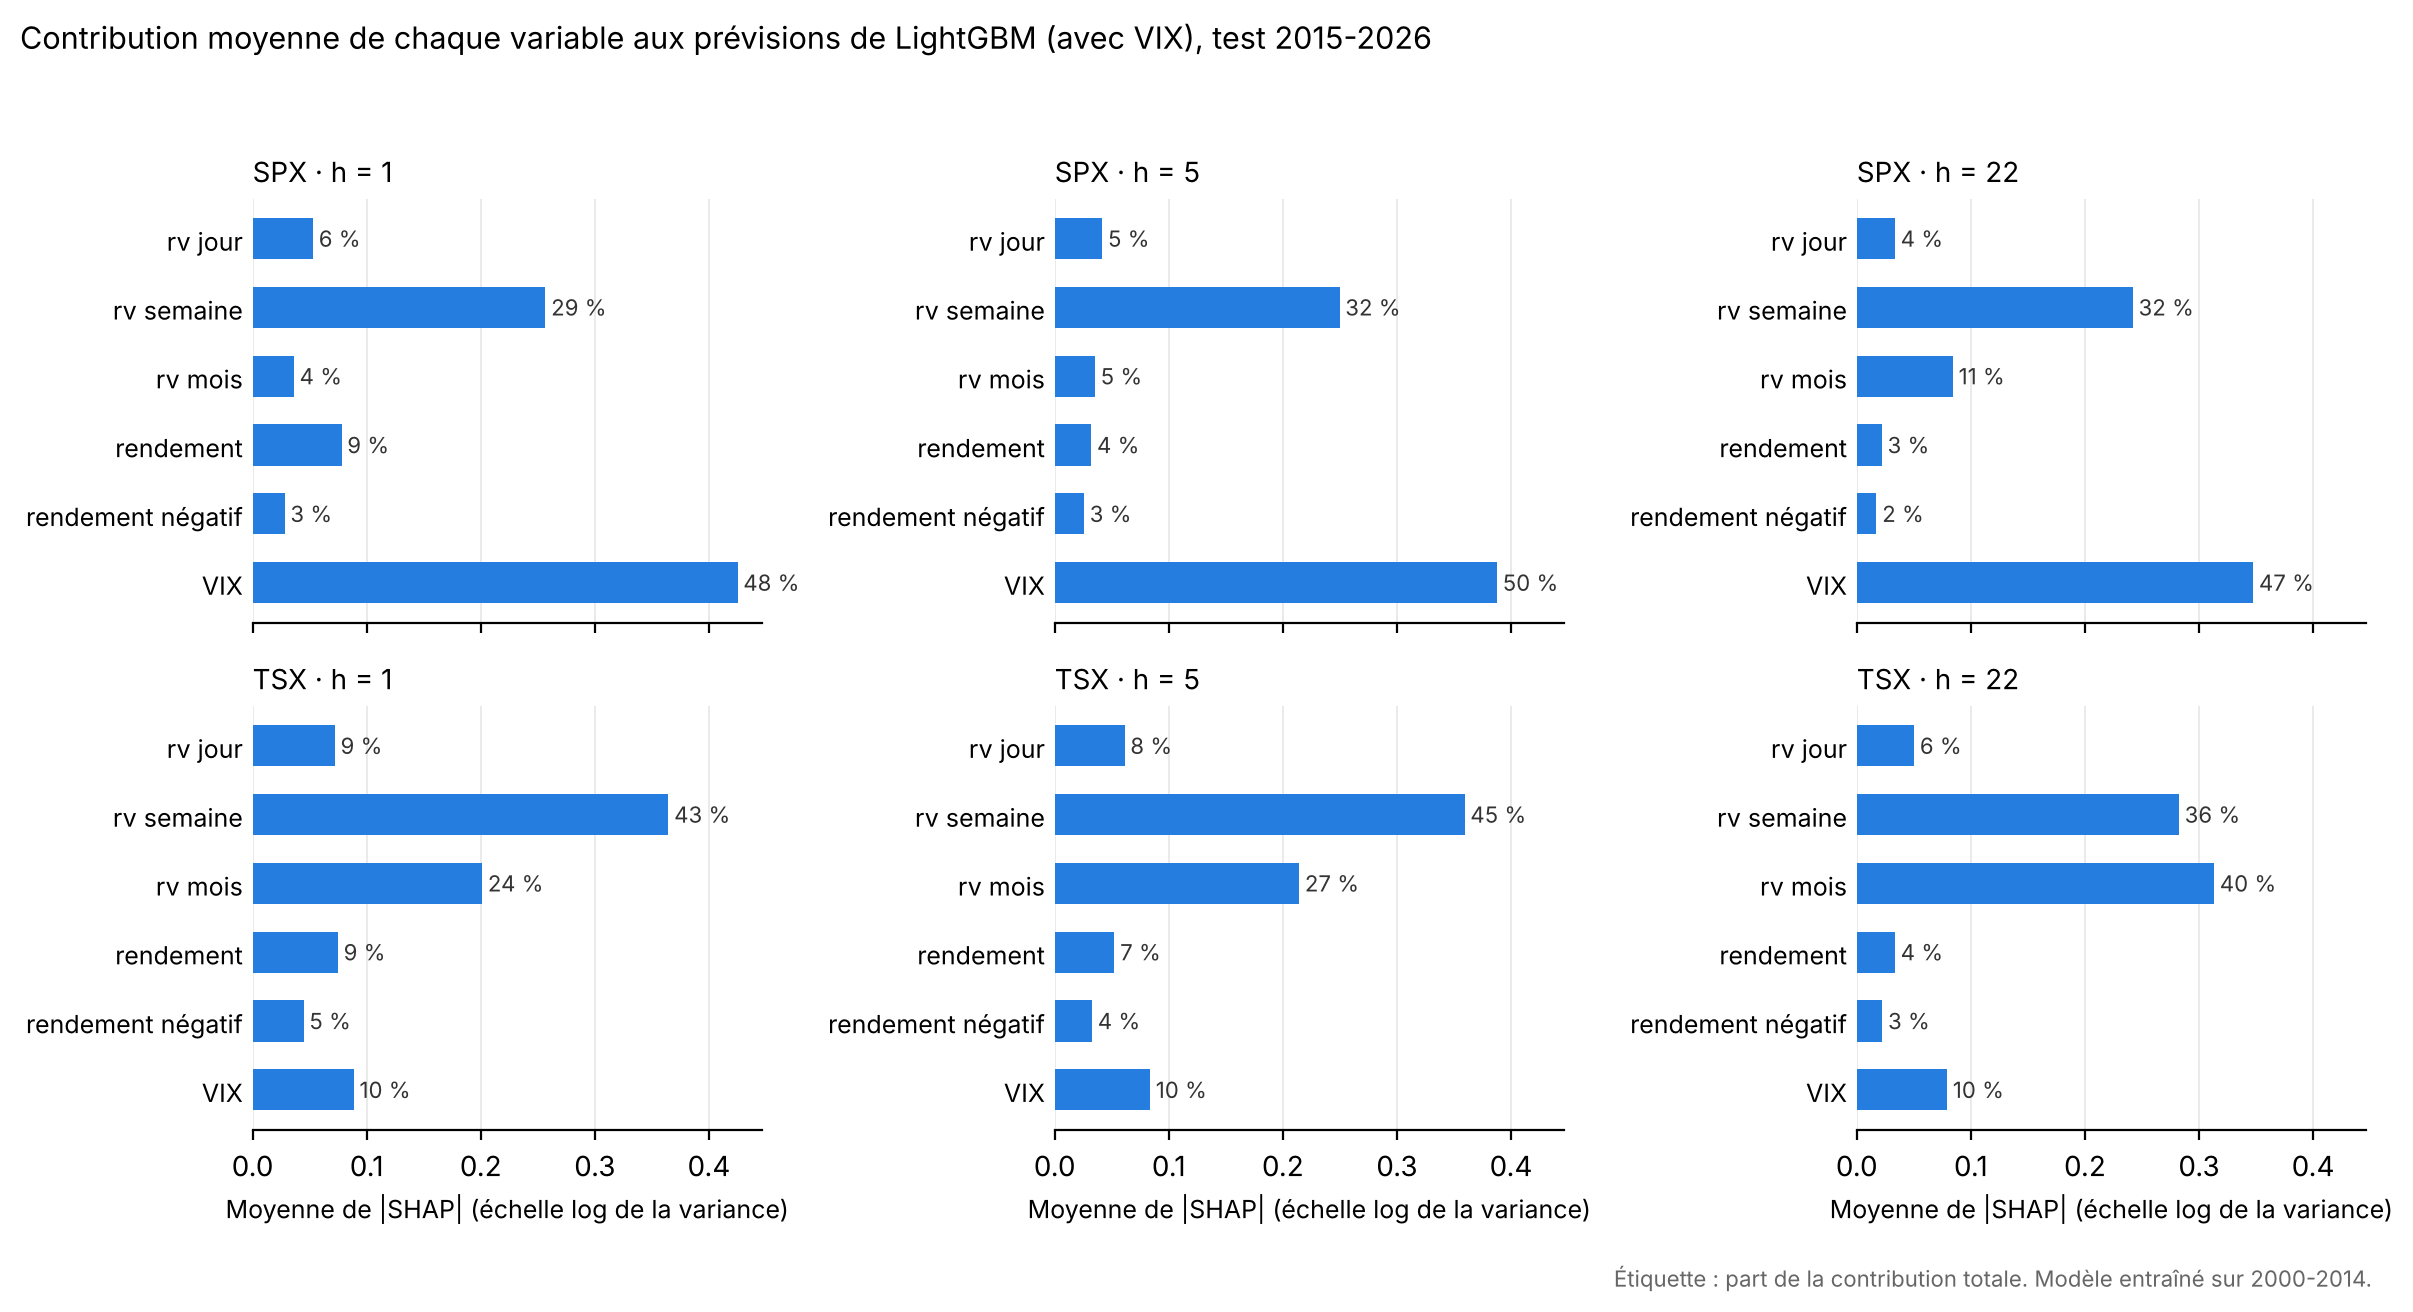

In [8]:
BLEU = "#257de0"
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True)
for i, ix in enumerate(("spx", "tsx")):
    for j, h in enumerate(HORIZONS):
        ax = axes[i, j]
        g = table12[(table12["indice"] == ix) & (table12["horizon"] == h)].set_index("variable").reindex(X_COLS)
        y = range(len(X_COLS))
        ax.barh(y, g["moyenne_abs_SHAP"], height=0.6, color=BLEU)
        for yy, v, s in zip(y, g["moyenne_abs_SHAP"], g["part_%"]):
            ax.text(v + 0.005, yy, f"{s:.0f} %", va="center", fontsize=8, color="#333333")
        ax.set_yticks(list(y)); ax.set_yticklabels([NOMS[c] for c in X_COLS], fontsize=9)
        ax.invert_yaxis()
        ax.set_title(f"{ix.upper()} · h = {h}", fontsize=10, loc="left")
        ax.grid(axis="x", color="#e6e6e6", lw=0.6); ax.set_axisbelow(True)
        for s_ in ("top", "right", "left"): ax.spines[s_].set_visible(False)
        ax.tick_params(axis="y", length=0)
for ax in axes[1]: ax.set_xlabel("Moyenne de |SHAP| (échelle log de la variance)", fontsize=9)
fig.suptitle("Contribution moyenne de chaque variable aux prévisions de LightGBM (avec VIX), test 2015-2026",
             fontsize=11, x=0.01, ha="left")
fig.text(0.99, 0.005, "Étiquette : part de la contribution totale. Modèle entraîné sur 2000-2014.",
         ha="right", fontsize=8, color="#666666")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(root / "figures" / "fig6_shap.png", dpi=150)
plt.show()

## Synthèse

**1. LightGBM contre la famille GARCH (table 7).** LightGBM est significativement meilleur que GARCH, GJR et EGARCH à h = 1 sur les deux indices (p ≤ 0,0002) et à h = 5 sur le S&P 500 (p ≤ 0,004). Sur le TSX à h = 5, il bat le GARCH (p = 0,0003) et le GJR (p = 0,018), mais pas significativement l'EGARCH (p = 0,054). À h = 22, aucune différence n'est significative.

**2. Sous-périodes (table 8).** Contre le HAR, le gain de LightGBM à h = 1 et 5 est présent dans les trois périodes (de −6,6 % à −27,3 %), significatif partout sauf en 2020 pour le S&P 500 à h = 1 (p = 0,18) et à h = 5 (p = 0,063), et pour le TSX à h = 5 (p = 0,59). À h = 22, le signe change selon la période (TSX : −42,9 % en 2015-2019, +74,7 % en 2020) : aucune conclusion stable. Contre le log-HAR-X, l'avantage dépend du régime : en période calme (2015-2019), le log-HAR-X est meilleur sur le S&P 500 à h = 5 (+6,6 % pour LightGBM, p = 0,001) et h = 22 (+20,0 %, p = 0,017) ; en 2020, LightGBM est meilleur sur le S&P 500 à h = 5 (−10,6 %, p = 0,029) et sur le TSX à h = 1 (−13,0 %, p = 0,002) ; en 2021-2026, aucune différence à h = 1 et 5 (p ≥ 0,43). La non-linéarité semble surtout utile pendant les crises, et ces deux effets se compensent sur l'ensemble de la période.

**3. Tests multiples (table 9).** Sur les 84 tests de Diebold-Mariano du projet, 37 rejettent l'égalité à 5 % sans correction et 24 après la correction de Holm. Les résultats principaux survivent : LightGBM bat le HAR à h = 1 et 5 sur les deux indices, et le log-HAR-X aussi (p corrigées < 0,001). Ne survivent pas, entre autres : l'apport du VIX à LightGBM sur le S&P 500 à h = 5 et sur le TSX à h = 1 (seul celui du S&P 500 à h = 1 survit), LightGBM contre GJR et EGARCH à h = 5, le GARCH(1,1) moins bon que le HAR, LightGBM sans VIX contre le log-HAR à h = 1 et le log-HAR-X meilleur que LightGBM à h = 22 sur le S&P 500. Dans la famille restreinte à la question de recherche (12 tests), ce dernier résultat ne survit pas non plus (p corrigée = 0,22).

**4. Grille élargie (table 10).** Avec num_leaves jusqu'à 3 et min_child_samples jusqu'à 10, la validation croisée choisit presque toujours des valeurs plus petites qu'avant, souvent encore au bord de la nouvelle grille, et sa QLIKE baisse. Mais la QLIKE de test change très peu (de −4,7 % à +0,8 %) et la différence avec le modèle de T11 n'est significative que dans 2 cas sur 12. Contre le log-HAR-X, LightGBM avec VIX reste non significativement différent à h = 1 et 5. Le fait que la grille touche son bord ne change donc pas les conclusions ; le gain de validation croisée ne se transmet pas à la période de test.

**5. Donnée du TSX du 2008-10-14 (table 11).** Ramener cette valeur à la deuxième plus grande améliore la QLIKE du HAR en niveaux de 4 à 7 %, mais ne change presque rien pour le log-HAR-X et LightGBM (moins de 0,7 %). Le HAR en niveaux, estimé par MCO, est sensible à un seul point extrême ; le log et les arbres ne le sont pas. Une partie de l'avance de LightGBM sur le HAR au TSX vient donc de ce point : à h = 1, l'écart passe de −13,1 % à −9,2 %, toujours significatif (p < 0,001). Les conclusions contre le log-HAR-X ne changent pas.

**6. SHAP (table 12, figure 6).** Pour le S&P 500, le VIX fournit environ la moitié de la contribution totale (46 à 50 %), devant rv semaine (29 à 32 %). Pour le TSX, le VIX ne pèse qu'environ 10 % ; ce sont rv semaine et rv mois qui dominent, rv mois devenant la première variable à h = 22 (40 %). C'est cohérent avec les élasticités du log-HAR-X (environ 1,6 contre 0,4) : le VIX, indice américain, renseigne beaucoup moins sur le marché canadien. Les rendements (ret, ret_neg) pèsent peu (5 à 14 % à eux deux).